# Clustering TCR Sequences

Following featurization of the TCRSeq data, users will often want to cluster the TCRSeq data to identify possible antigen-specific clusters of sequences. In order to do this, we have provided multiple ways for clustering your TCR sequences.

## Phenograph Clustering

The first method we will explore is using a network-graph based clustering algorithm called Phenograph (https://github.com/jacoblevine/PhenoGraph). This method automatically determines the number of clusters in the data by maximizing the modularity of the network-graph asssembled from the data. Of note, this algorithm is very fast and will be useful for when there are possibly thousands to tens of thouands of sequences to cluster. However, clusters by this method tend to be quite large.

First, we will load data and train the VAE.

In [1]:
%%capture
import sys
sys.path.append('../../')
from DeepTCR.DeepTCR import DeepTCR_U

# Instantiate training object
DTCRU = DeepTCR_U('Tutorial')

#Load Data from directories
DTCRU.Get_Data(directory='../../Data/Murine_Antigens',Load_Prev_Data=False,aggregate_by_aa=True,
               aa_column_beta=0,count_column=1,v_beta_column=2,j_beta_column=3)

#Train VAE
DTCRU.Train_VAE(Load_Prev_Data=False)


Metal device set to: Apple M3 Max


We will then run the clustering command.

In [2]:
DTCRU.Cluster(clustering_method='phenograph')

Finding 30 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.30678677558898926 seconds
Jaccard graph constructed in 0.3061041831970215 seconds
Wrote graph to binary file in 0.014518976211547852 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.847197
After 3 runs, maximum modularity is Q = 0.849238
After 5 runs, maximum modularity is Q = 0.850781
Louvain completed 25 runs in 1.3821330070495605 seconds
PhenoGraph complete in 2.0144810676574707 seconds
Clustering Done


Following clustering, we can view the clustering solutions by looking at the object variable called Cluster_DFs.

In [3]:
DFs = DTCRU.Cluster_DFs
print(DFs[0])

     index Alpha_Sequences   Beta_Sequences V_alpha J_alpha      V_beta  \
0        3            None   CASSIGQYNSPLYF    None    None  TCRBV19-01   
1       25            None    CASSPGASSDYTF    None    None  TCRBV19-03   
2       27            None    CASSPGANSDYTF    None    None  TCRBV19-03   
3       48            None   CASSQGQIGSDYTF    None    None  TCRBV19-03   
4       49            None    CASSQGAYSDYTF    None    None  TCRBV19-03   
..     ...             ...              ...     ...     ...         ...   
206   2390            None      CASSQGPDYTF    None    None  TCRBV26-01   
207   2395            None   CASSTGRNQNTLYF    None    None  TCRBV17-01   
208   2396            None   CASSTGTPNSDYTF    None    None  TCRBV19-01   
209   2413            None  CASRSGGGGQNTLYF    None    None  TCRBV15-01   
210   2431            None    CASSINRGNTLYF    None    None  TCRBV19-01   

    D_beta      J_beta  Frequency   Labels       Sample           HLA  
0     None  TCRBJ01-06   0.

We can also choose to save these results to a directory called Name of object + '_Results' by setting the write_to_sheets parameter to True. There, we can find the proportions of every sample in each cluster and csv files for every cluster detailing the sequence information with other information as well.

In [4]:
DTCRU.Cluster(clustering_method='phenograph',write_to_sheets=True)

Finding 30 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.29021596908569336 seconds
Jaccard graph constructed in 0.31110239028930664 seconds
Wrote graph to binary file in 0.01413416862487793 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.848884
After 3 runs, maximum modularity is Q = 0.85016
After 16 runs, maximum modularity is Q = 0.851402
Louvain completed 36 runs in 1.7457077503204346 seconds
PhenoGraph complete in 2.3663289546966553 seconds
Clustering Done


We can also employ two other clustering algorithms (hierarchical clustering and DBSCAN). For these types of methods, we can either control the settings for the algorithm such as the threshold parameter (t), the criterion/linkage algorithm for heirarchical clustering, or we can allow the method to determine the optimal threshold parameter by maximizing the silhoutte score of the clustering solution. First, if we run hierarchial clustering letting the program determing the right threshold parameters:

## Hierarchical Clustering

In [5]:
DTCRU.Cluster(clustering_method='hierarchical')

/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fra

Clustering Done


/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fra

Or we can set the parameters ourselves.

In [6]:
DTCRU.Cluster(clustering_method='hierarchical',criterion='distance',t=1.0)

/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fra

Clustering Done


/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  DF_Sum['Cluster_' + str(i)] = df_sum
/Users/ali/Downloads/Maj_Papers/New TCR/OldDeepTCR/DeepTCR-master/DeepTCR/DeepTCR.py:1125: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fra

## DBSCAN clustering

And to use DBSCAN...

In [7]:
DTCRU.Cluster(clustering_method='dbscan')

Clustering Done


In the case there are perhaps too many sequences to efficiently cluster the data quickly, one can downsample the data and then use a k-nearest neighbor algorithm to classify the rest of the sequences like so .Here, we will downsample 500 sequenes for clustering and then assign the rest via KNN.

In [8]:
DTCRU.Cluster(clustering_method='phenograph',sample=500)

Finding 30 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.11145997047424316 seconds
Jaccard graph constructed in 0.15649700164794922 seconds
Wrote graph to binary file in 0.0032613277435302734 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.602159
After 2 runs, maximum modularity is Q = 0.605336
After 3 runs, maximum modularity is Q = 0.607805
Louvain completed 23 runs in 1.0871000289916992 seconds
PhenoGraph complete in 1.3633341789245605 seconds
Clustering Done


Finally, we can visualize the clustering results through a UMAP representation of the sequences.

## Clustering Visualization

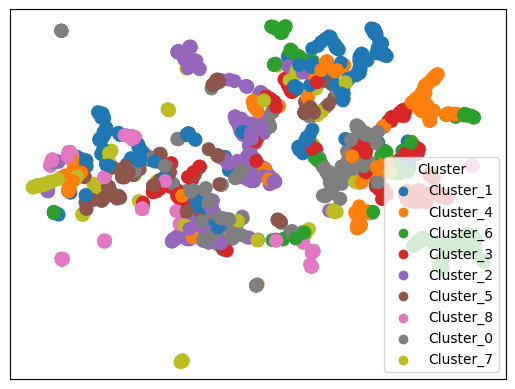

In [9]:
DTCRU.UMAP_Plot(by_cluster=True)

For full description of options for clustering, see Documentation.